# Rossmann Store Sales - Modeling Notebook
#### The task is to forecast the "Sales" column for the test set.

In [4]:
# Data manipulation and visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Utilities
import time

# Scikit-learn: Base classes and utilities
from sklearn.base import BaseEstimator, TransformerMixin, clone

# Scikit-learn: Pipeline and column transformations
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Scikit-learn: Preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)

# Scikit-learn: Models
from sklearn.ensemble import RandomForestRegressor

## 1. Load Data

In [5]:
# Load datasets
train_data = pd.read_csv(
    "../Data/train.csv",
    dtype={"StateHoliday": str}
)

store_data = pd.read_csv("../Data/store.csv")

# Merge store information
train_data = train_data.merge(
    store_data,
    on="Store",
    how="left"
)

# Remove Customers (not available in test data)
train_data = train_data.drop(columns=["Customers"])

# Convert Date to datetime
train_data["Date"] = pd.to_datetime(train_data["Date"])

# Reset index
train_data = train_data.reset_index(drop=True)

train_data.head()

,Store,DayOfWeek,Date,Sales,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [6]:
print("Train shape:", train_data.shape)

print("Store shape:", store_data.shape)

print("\nTrain columns:")
print(train_data.columns.tolist())

# Column definitions based on Kaggle dataset documentation
column_definitions = {
    "Store": "Unique ID for each store.",
    "DayOfWeek": "Day of the week (1 = Monday, ..., 7 = Sunday).",
    "Date": "Date of the record (YYYY-MM-DD).",
    "Sales": "The turnover for any given day (target variable).",
    "Customers": "The number of customers on a given day (in train, not in test).",
    "Open": "Indicator for whether the store was open: 0 = closed, 1 = open.",
    "Promo": "Indicates whether a store is running a promotion on that day. Promo = 0 → No promotion was running that day. Promo = 1 → The store was running a promotion that day.",
    "StateHoliday": "Indicates a state holiday: a = public holiday, b = Easter holiday, c = Christmas, 0 = None.",
    "SchoolHoliday": "Indicates if the store/date was affected by public school closures.",
    "StoreType": "Differentiates between 4 different store models: a, b, c, d.",
    "Assortment": "Describes an assortment level: a = basic, b = extra, c = extended.",
    "CompetitionDistance": "Distance in meters to the nearest competitor store.",
    "CompetitionOpenSinceMonth": "Approximate month when nearest competitor opened.",
    "CompetitionOpenSinceYear": "Approximate year when nearest competitor opened.",
    "Promo2": "Continuing and consecutive promotion: 0 = not participating, 1 = participating.",
    "Promo2SinceWeek": "Calendar week when the store started participating in Promo2.",
    "Promo2SinceYear": "Year when the store started participating in Promo2.",
    "PromoInterval": "Consecutive intervals at which Promo2 runs (e.g. 'Jan,Apr,Jul,Oct').",
}


Train shape: (1017209, 17)
Store shape: (1115, 10)

Train columns:
['Store', 'DayOfWeek', 'Date', 'Sales', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']


In [7]:
print("Train missing values:")
display(train_data.isnull().sum().sort_values(ascending=False))

Train missing values:


PromoInterval                508031
Promo2SinceYear              508031
Promo2SinceWeek              508031
CompetitionOpenSinceMonth    323348
CompetitionOpenSinceYear     323348
CompetitionDistance            2642
Store                             0
DayOfWeek                         0
Date                              0
StoreType                         0
SchoolHoliday                     0
StateHoliday                      0
Promo                             0
Open                              0
Sales                             0
Assortment                        0
Promo2                            0
dtype: int64

In [8]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 17 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[us]
 3   Sales                      1017209 non-null  int64         
 4   Open                       1017209 non-null  int64         
 5   Promo                      1017209 non-null  int64         
 6   StateHoliday               1017209 non-null  str           
 7   SchoolHoliday              1017209 non-null  int64         
 8   StoreType                  1017209 non-null  str           
 9   Assortment                 1017209 non-null  str           
 10  CompetitionDistance        1014567 non-null  float64       
 11  CompetitionOpenSinceMonth  693861 non-null   flo

In [9]:
# Check date ranges
print("Train date range:")
print(train_data["Date"].min(), "to", train_data["Date"].max())

# Check unique stores
print("\nUnique stores:")
print("Train:", train_data["Store"].nunique())

# Check duplicate store-date combinations
print("\nDuplicate records:")
print("Train:", train_data.duplicated(["Store", "Date"]).sum())

Train date range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Unique stores:
Train: 1115

Duplicate records:
Train: 0


In [10]:
train_data["Sales"].describe()

print("Zero sales:", (train_data["Sales"] == 0).sum())
print("Positive sales:", (train_data["Sales"] > 0).sum())
print("Maximum sales:", train_data["Sales"].max())
print("Mean sales:", train_data["Sales"].mean())
print("Median sales:", train_data["Sales"].median())

Zero sales: 172871
Positive sales: 844338
Maximum sales: 41551
Mean sales: 5773.818972305593
Median sales: 5744.0


## 2. EDA

In [11]:
# Sales distribution by store status
display(
    train_data.groupby("Open")["Sales"]
    .agg(["count", "mean", "median", "min", "max"])
)

,count,mean,median,min,max
Open,,,,,
0,172817,0.000000,0.0,0,0
1,844392,6955.514291,6369.0,0,41551


In [12]:
# Check closed stores with positive sales
print(
    "Closed stores with positive sales:",
    ((train_data["Open"] == 0) & (train_data["Sales"] > 0)).sum()
)

# Check open stores with zero sales
print(
    "Open stores with zero sales:",
    ((train_data["Open"] == 1) & (train_data["Sales"] == 0)).sum()
)

Closed stores with positive sales: 0
Open stores with zero sales: 54


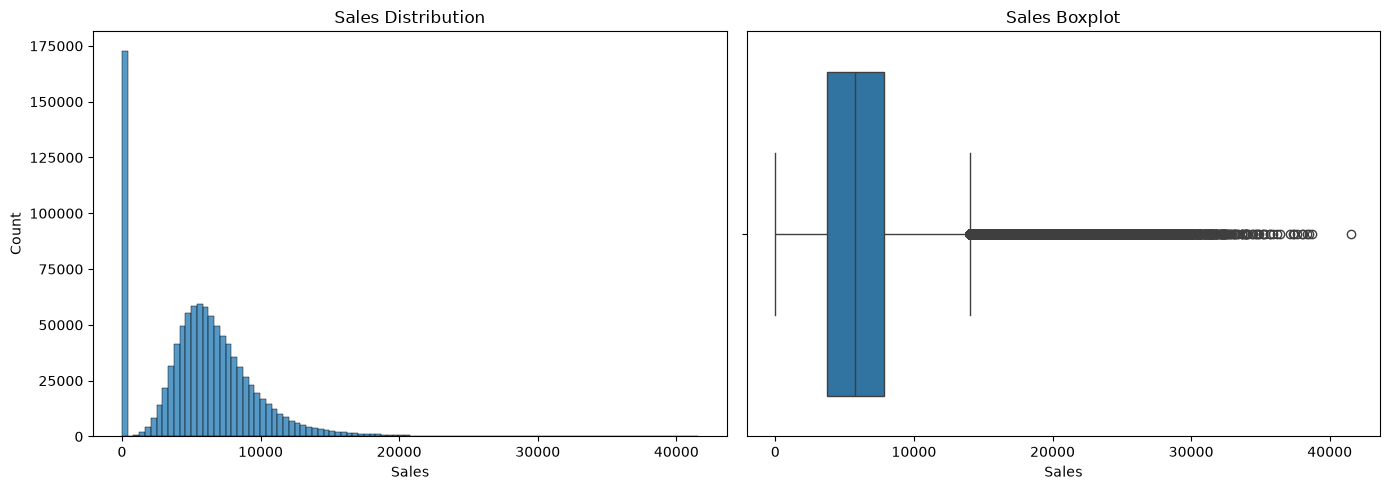

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sales distribution
sns.histplot(
    data=train_data,
    x="Sales",
    bins=100,
    ax=axes[0]
)
axes[0].set_title("Sales Distribution")

# Sales boxplot
sns.boxplot(
    data=train_data,
    x="Sales",
    ax=axes[1]
)
axes[1].set_title("Sales Boxplot")

plt.tight_layout()
plt.show()

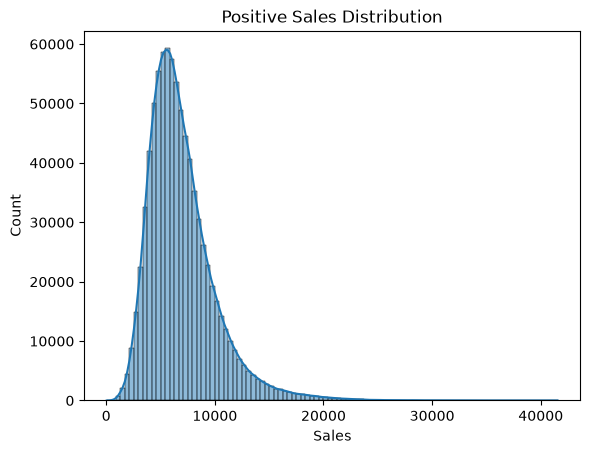

In [14]:
sns.histplot(
    data=train_data.loc[train_data["Sales"] > 0, "Sales"],
    bins=100,
    kde=True
)

plt.title("Positive Sales Distribution")
plt.xlabel("Sales")
plt.show()

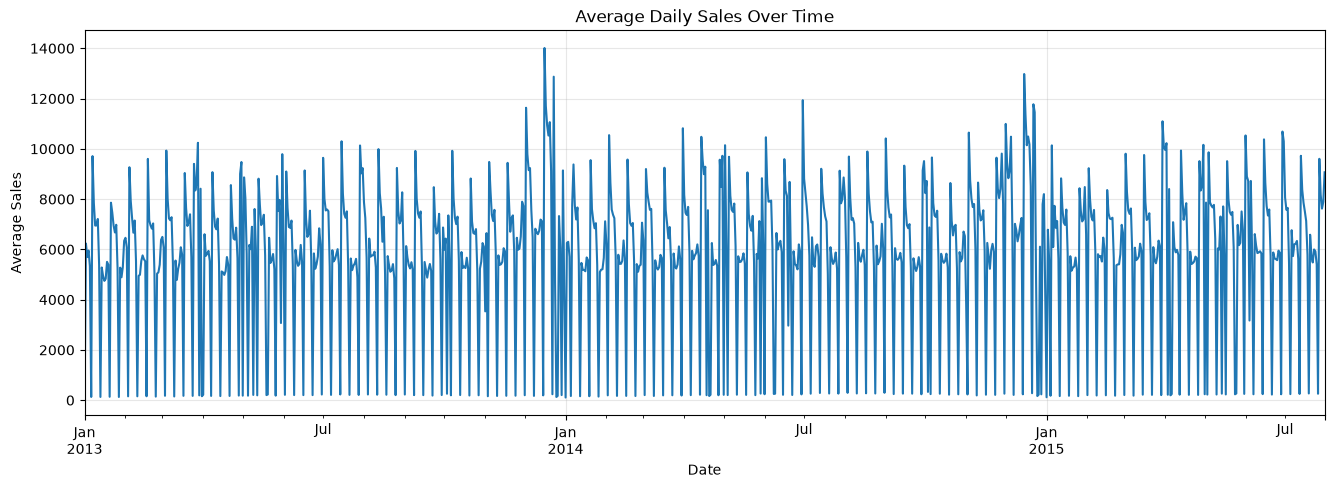

In [15]:
daily_sales = (
    train_data.groupby("Date")["Sales"]
    .mean()
)

plt.figure(figsize=(16, 5))
daily_sales.plot()

plt.title("Average Daily Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Average Sales")
plt.grid(alpha=0.3)
plt.show()

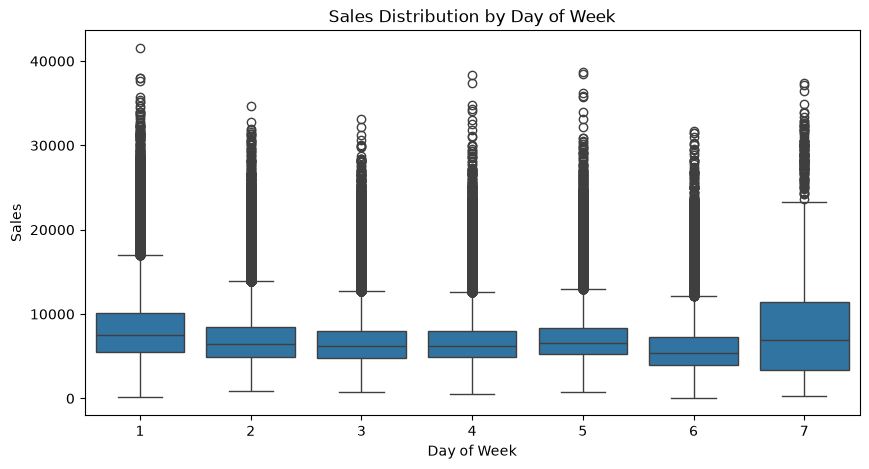

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=train_data.loc[train_data["Sales"] > 0],
    x="DayOfWeek",
    y="Sales"
)

plt.title("Sales Distribution by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Sales")
plt.show()

DayOfWeek
1    8216.252259
2    7088.409086
3    6728.786679
4    6768.214973
5    7073.034133
6    5875.084935
7    8224.723908
Name: Sales, dtype: float64

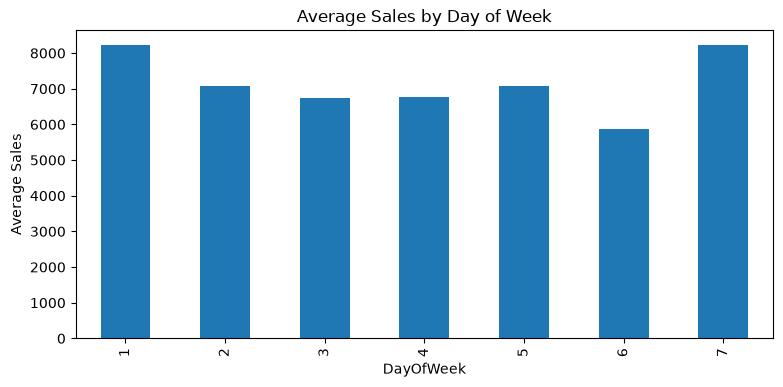

In [17]:
day_sales = (
    train_data.loc[train_data["Sales"] > 0]
    .groupby("DayOfWeek")["Sales"]
    .mean()
)

display(day_sales)

day_sales.plot(kind="bar", figsize=(9, 4))
plt.title("Average Sales by Day of Week")
plt.ylabel("Average Sales")
plt.show()

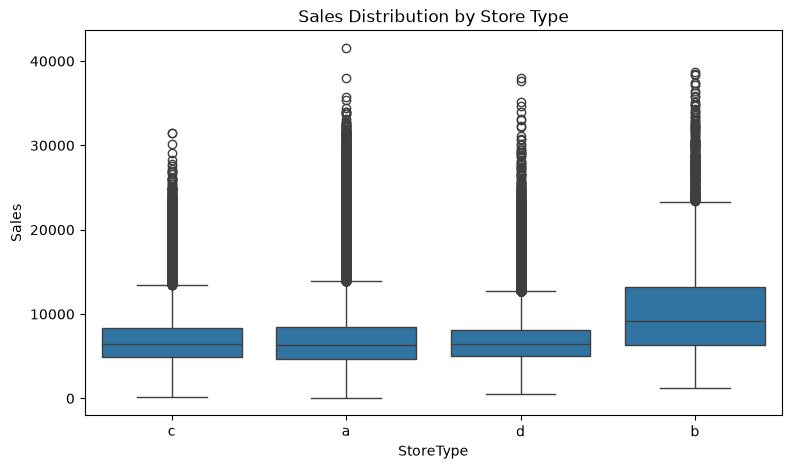

In [18]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_data.loc[train_data["Sales"] > 0],
    x="StoreType",
    y="Sales"
)

plt.title("Sales Distribution by Store Type")
plt.show()

In [19]:
promo_sales = (
    train_data.loc[train_data["Sales"] > 0]
    .groupby("Promo")["Sales"]
    .agg(["mean", "median", "count"])
)

display(promo_sales)

,mean,median,count
Promo,,,
0,5929.826183,5459.0,467463
1,8228.739731,7650.0,376875


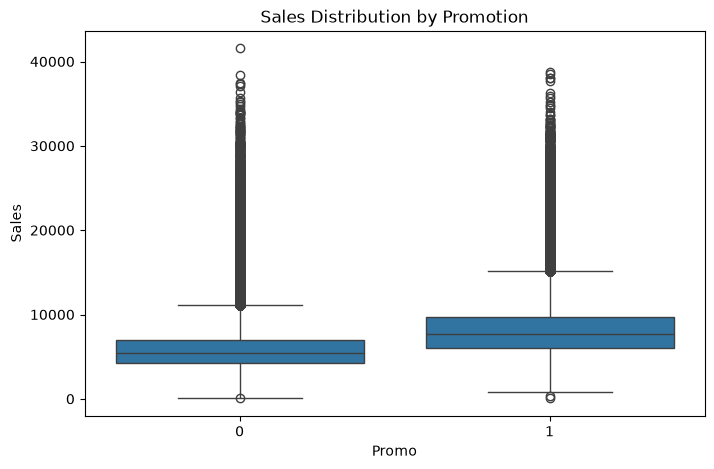

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=train_data.loc[train_data["Sales"] > 0],
    x="Promo",
    y="Sales"
)

plt.title("Sales Distribution by Promotion")
plt.show()

In [21]:
holiday_sales = (
    train_data.loc[train_data["Sales"] > 0]
    .groupby("StateHoliday")["Sales"]
    .agg(["mean", "median", "count"])
)

display(holiday_sales)

,mean,median,count
StateHoliday,,,
0,6953.960229,6368.0,843428
a,8487.471182,7556.0,694
b,9887.889655,8423.0,145
c,9743.746479,8397.0,71


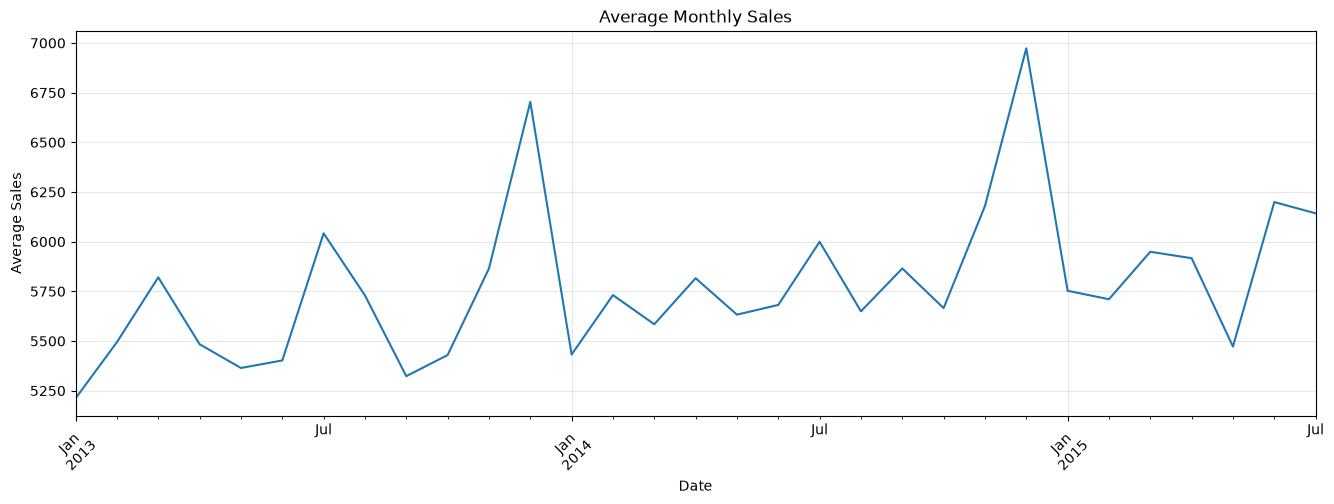

In [22]:
monthly_sales = (
    train_data
    .groupby(train_data["Date"].dt.to_period("M"))["Sales"]
    .mean()
)

plt.figure(figsize=(16, 5))

monthly_sales.plot()

plt.title("Average Monthly Sales")
plt.xlabel("Date")
plt.ylabel("Average Sales")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.show()

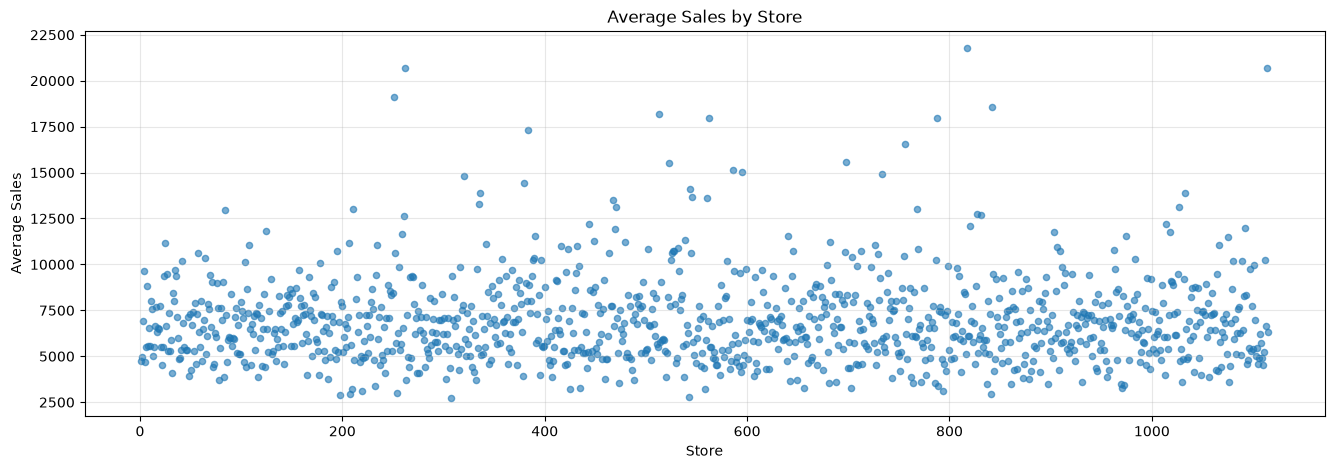

In [23]:
store_sales = (
    train_data.loc[train_data["Sales"] > 0]
    .groupby("Store")["Sales"]
    .mean()
)

plt.figure(figsize=(16, 5))

# Scatter plot: Store ID on x-axis, Average Sales on y-axis
plt.scatter(store_sales.index, store_sales.values, alpha=0.6, s=20, color="tab:blue")

plt.title("Average Sales by Store")
plt.xlabel("Store")
plt.ylabel("Average Sales")
plt.grid(alpha=0.3)
plt.show()

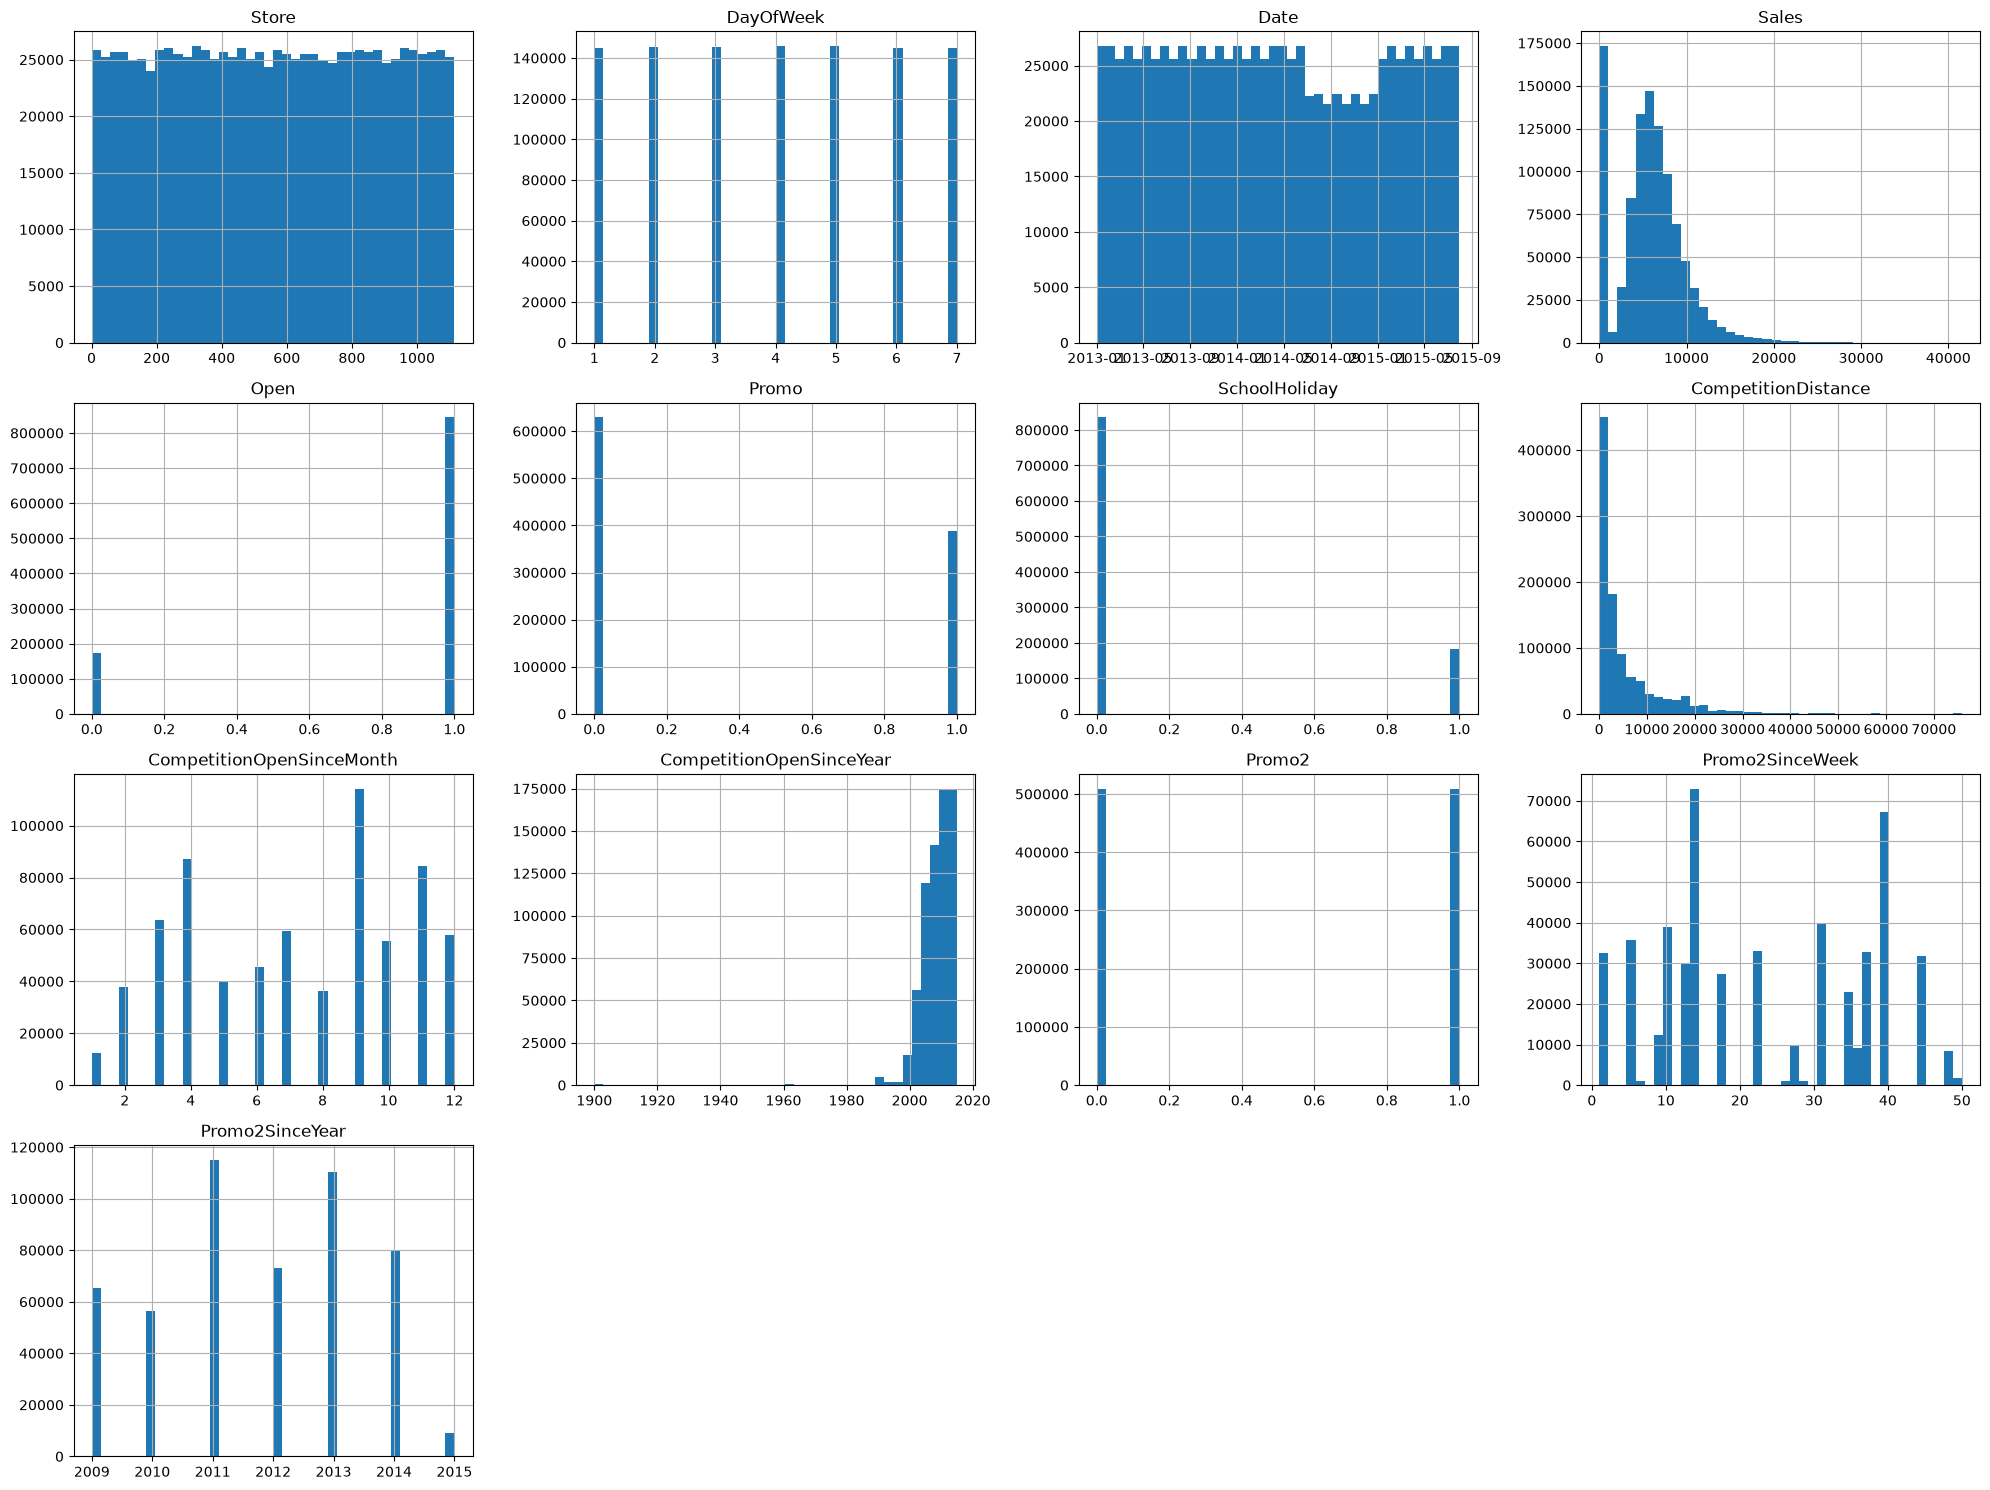

In [24]:
train_data.hist(bins=40, figsize=(20, 15))
plt.tight_layout()
plt.show()

## 3. Feature Engineering

In [25]:
class RossmannFeatureEngineer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        # Learn CompetitionDistance median from training data
        self.competition_distance_median_ = X["CompetitionDistance"].median()
        if pd.isna(self.competition_distance_median_):
            self.competition_distance_median_ = 0
        return self

    def transform(self, X):
        X = X.copy()

        # Ensure Date is datetime
        X["Date"] = pd.to_datetime(X["Date"])

        # ==================================================
        # 1. Calendar / Temporal Features
        # ==================================================
        X["Year"] = X["Date"].dt.year
        X["Month"] = X["Date"].dt.month
        X["Day"] = X["Date"].dt.day
        X["DayOfYear"] = X["Date"].dt.day_of_year
        X["WeekOfYear"] = X["Date"].dt.isocalendar().week.astype(int)
        X["Quarter"] = X["Date"].dt.quarter

        X["IsWeekend"] = X["DayOfWeek"].isin([6, 7]).astype(int)
        X["IsMonthStart"] = X["Date"].dt.is_month_start.astype(int)
        X["IsMonthEnd"] = X["Date"].dt.is_month_end.astype(int)

        # ==================================================
        # 2. Competition Features
        # ==================================================
        X["HasCompetitionInfo"] = (
            X["CompetitionOpenSinceYear"].notna()
            & X["CompetitionOpenSinceMonth"].notna()
        ).astype(int)

        # Calculate competition opening date in months
        competition_open_month = (
            X["CompetitionOpenSinceYear"] * 12
            + X["CompetitionOpenSinceMonth"]
        )

        current_month = (
            X["Date"].dt.year * 12
            + X["Date"].dt.month
        )

        # Months since competition opened
        X["CompetitionOpenMonths"] = (
            current_month - competition_open_month
        ).clip(lower=0).fillna(0)

        # Impute missing competition distance using training median
        X["CompetitionDistance"] = X["CompetitionDistance"].fillna(
            self.competition_distance_median_
        )

        # ==================================================
        # 3. Promo2 Features
        # ==================================================

        # ISO year and week
        iso_date = X["Date"].dt.isocalendar()

        current_iso_year = iso_date.year
        current_iso_week = iso_date.week

        # Check whether Promo2 has started
        promo_started = (
            (current_iso_year > X["Promo2SinceYear"])
            | (
                (current_iso_year == X["Promo2SinceYear"])
                & (current_iso_week >= X["Promo2SinceWeek"])
            )
        )

        # Convert month abbreviations to Rossmann format
        current_month_name = X["Date"].dt.strftime("%b")

        # Parse PromoInterval into sets of months
        promo_months = X["PromoInterval"].fillna("").apply(
            lambda x: set(x.split(","))
        )

        # Check whether current month is in PromoInterval
        active_month = pd.Series(
            [
                month in interval
                for month, interval in zip(
                    current_month_name, promo_months
                )
            ],
            index=X.index
        )

        # Promo2 is active only when:
        # 1. The store participates in Promo2
        # 2. The promotion has already started
        # 3. The current month is included in PromoInterval
        X["Promo2Active"] = (
            (X["Promo2"] == 1)
            & promo_started
            & active_month
        ).astype(int)

        return X

In [26]:
feature_engineer = RossmannFeatureEngineer()

train_features = feature_engineer.fit_transform(train_data)

new_features = [
    "Year",
    "Month",
    "Day",
    "DayOfYear",
    "WeekOfYear",
    "Quarter",
    "IsWeekend",
    "IsMonthStart",
    "IsMonthEnd",
    "HasCompetitionInfo",
    "CompetitionOpenMonths",
    "Promo2Active"
]

train_features[new_features].describe()

,Year,Month,Day,DayOfYear,WeekOfYear,Quarter,IsWeekend,IsMonthStart,IsMonthEnd,HasCompetitionInfo,CompetitionOpenMonths,Promo2Active
count,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06,1.017209e+06
mean,2.013832e+03,5.846762e+00,1.570279e+01,1.622764e+02,2.361551e+01,2.294252e+00,2.845630e-01,3.291752e-02,3.291851e-02,6.821224e-01,4.203993e+01,1.444433e-01
std,7.773960e-01,3.326097e+00,8.787638e+00,1.016162e+02,1.443338e+01,1.081850e+00,4.512063e-01,1.784208e-01,1.784234e-01,4.656519e-01,6.534447e+01,3.515388e-01
min,2.013000e+03,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2.013000e+03,3.000000e+00,8.000000e+00,7.700000e+01,1.100000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.014000e+03,6.000000e+00,1.600000e+01,1.530000e+02,2.200000e+01,2.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.600000e+01,0.000000e+00
75%,2.014000e+03,8.000000e+00,2.300000e+01,2.410000e+02,3.500000e+01,3.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,7.300000e+01,0.000000e+00
max,2.015000e+03,1.200000e+01,3.100000e+01,3.650000e+02,5.200000e+01,4.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.386000e+03,1.000000e+00


In [27]:
train_features[new_features].head()

,Year,Month,Day,DayOfYear,WeekOfYear,Quarter,IsWeekend,IsMonthStart,IsMonthEnd,HasCompetitionInfo,CompetitionOpenMonths,Promo2Active
0,2015,7,31,212,31,3,0,0,1,1,82.0,0
1,2015,7,31,212,31,3,0,0,1,1,92.0,1
2,2015,7,31,212,31,3,0,0,1,1,103.0,1
3,2015,7,31,212,31,3,0,0,1,1,70.0,0
4,2015,7,31,212,31,3,0,0,1,1,3.0,0


In [28]:
train_features[new_features].isna().sum()

Year                     0
Month                    0
Day                      0
DayOfYear                0
WeekOfYear               0
Quarter                  0
IsWeekend                0
IsMonthStart             0
IsMonthEnd               0
HasCompetitionInfo       0
CompetitionOpenMonths    0
Promo2Active             0
dtype: int64

In [29]:
# Use open-store observations for analysis
X_skew = train_data.loc[
    train_data["Open"] == 1
].copy()

# Apply feature engineering
skew_engineer = RossmannFeatureEngineer()
X_skew = skew_engineer.fit_transform(X_skew)

# Remove target and non-feature columns
X_skew = X_skew.drop(
    columns=["Sales", "Customers", "Date", "Id", "Open"],
    errors="ignore"
)

# Select numerical features
numeric_data = X_skew.select_dtypes(include=np.number)

# Calculate skewness
skewness = numeric_data.skew().sort_values(
    ascending=False
)

skewness_df = pd.DataFrame({
    "Skewness": skewness,
    "Min": numeric_data.min(),
    "Max": numeric_data.max(),
    "Zeros": (numeric_data == 0).sum()
})

display(
    skewness_df.loc[
        skewness_df["Skewness"].abs() > 1
    ]
)

,Skewness,Min,Max,Zeros
CompetitionDistance,2.980058,20.0,75860.0,0
CompetitionOpenMonths,7.548298,0.0,1386.0,343310
CompetitionOpenSinceYear,-7.522105,1900.0,2015.0,0
IsMonthEnd,5.210298,0.0,1.0,816351
IsMonthStart,6.373452,0.0,1.0,825024
IsWeekend,1.711947,0.0,1.0,696741
Promo2Active,2.022179,0.0,1.0,722375
SchoolHoliday,1.551094,0.0,1.0,680935


## 4. Target Analysis & Validation Strategy

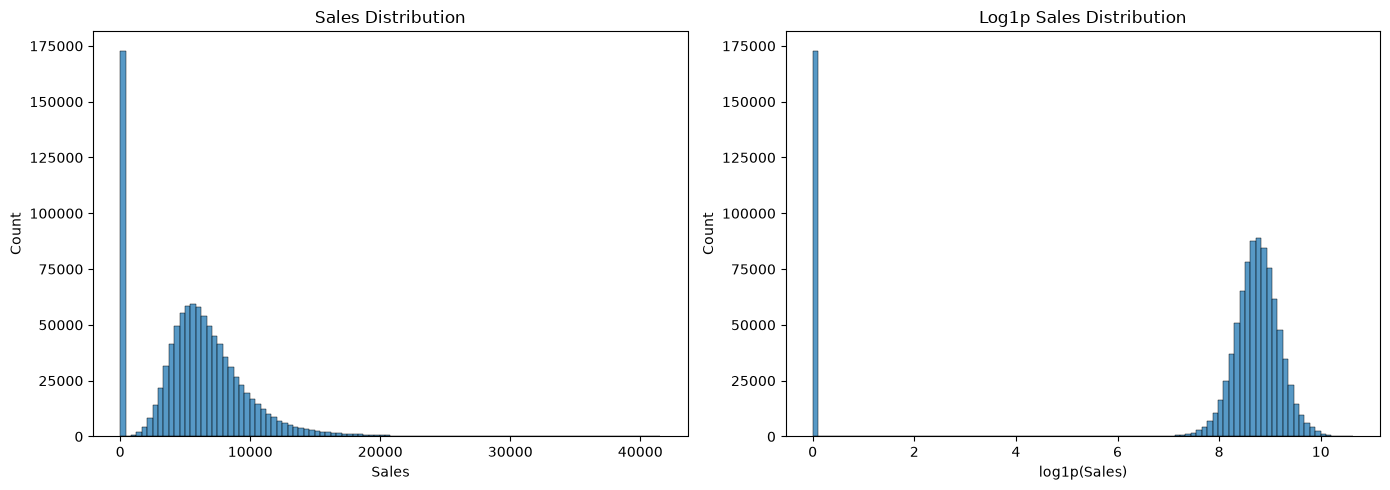

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original target distribution
sns.histplot(
    train_data["Sales"],
    bins=100,
    ax=axes[0]
)

axes[0].set_title("Sales Distribution")
axes[0].set_xlabel("Sales")

# Log-transformed target
sns.histplot(
    np.log1p(train_data["Sales"]),
    bins=100,
    ax=axes[1]
)

axes[1].set_title("Log1p Sales Distribution")
axes[1].set_xlabel("log1p(Sales)")

plt.tight_layout()
plt.show()

In [31]:
def rmspe(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mask = y_true != 0

    return np.sqrt(
        np.mean(
            ((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2
        )
    )

In [32]:
train_data = train_data.sort_values("Date").reset_index(drop=True)

# The last five months of the training data
last_month = train_data["Date"].max().replace(day=1)

validation_months = pd.date_range(
    end=last_month,
    periods=5,
    freq="MS"
)

folds = []

for fold, valid_start in enumerate(validation_months, start=1):

    valid_end = valid_start + pd.DateOffset(months=1)

    train_fold = train_data.loc[
        train_data["Date"] < valid_start
    ].copy()

    valid_fold = train_data.loc[
        (train_data["Date"] >= valid_start) &
        (train_data["Date"] < valid_end)
    ].copy()

    # Only open stores are used for training and validation
    train_fold = train_fold.loc[
        train_fold["Open"] == 1
    ].copy()

    valid_fold = valid_fold.loc[
        valid_fold["Open"] == 1
    ].copy()

    folds.append((train_fold, valid_fold))

    print(
        f"Fold {fold} | "
        f"Train: {train_fold['Date'].min().date()} "
        f"to {train_fold['Date'].max().date()} | "
        f"Validation: {valid_start.date()} "
        f"to {(valid_end - pd.Timedelta(days=1)).date()} | "
        f"Train size: {len(train_fold):,} | "
        f"Validation size: {len(valid_fold):,}"
    )

Fold 1 | Train: 2013-01-01 to 2015-02-28 | Validation: 2015-03-01 to 2015-03-31 | Train size: 703,890 | Validation size: 29,080
Fold 2 | Train: 2013-01-01 to 2015-03-31 | Validation: 2015-04-01 to 2015-04-30 | Train size: 732,970 | Validation size: 26,931
Fold 3 | Train: 2013-01-01 to 2015-04-30 | Validation: 2015-05-01 to 2015-05-31 | Train size: 759,901 | Validation size: 25,880
Fold 4 | Train: 2013-01-01 to 2015-05-31 | Validation: 2015-06-01 to 2015-06-30 | Train size: 785,781 | Validation size: 28,423
Fold 5 | Train: 2013-01-01 to 2015-06-30 | Validation: 2015-07-01 to 2015-07-31 | Train size: 814,204 | Validation size: 30,188


## 5. Preprocessing

In [33]:
# Get engineered feature columns
X_sample = feature_engineer.fit_transform(
    train_data.head(1000)
)

X_sample = X_sample.drop(
    columns=["Sales", "Date", "Id"],
    errors="ignore"
)

X_sample["Store"] = X_sample["Store"].astype(str)

numerical_features = X_sample.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_sample.select_dtypes(
    exclude=np.number
).columns.tolist()

print(len(X_sample.columns), "features in total")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))


for title, feats in [("Numerical features", numerical_features), ("Categorical features", categorical_features)]:
    print(f"{title}:")
    for i in range(0, len(feats), 5):
        print(" ", feats[i:i + 5])
    print()

27 features in total
Numerical features: 22
Categorical features: 5
Numerical features:
  ['DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'CompetitionDistance']
  ['CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear']
  ['Year', 'Month', 'Day', 'DayOfYear', 'WeekOfYear']
  ['Quarter', 'IsWeekend', 'IsMonthStart', 'IsMonthEnd', 'HasCompetitionInfo']
  ['CompetitionOpenMonths', 'Promo2Active']

Categorical features:
  ['Store', 'StateHoliday', 'StoreType', 'Assortment', 'PromoInterval']



### Numerical Features
#### 1. Store & Operations (Original Features)
* **`DayOfWeek`**: Integer day of the week (`1` = Monday through `7` = Sunday). Captures weekly cyclic shopping patterns.
* **`Open`**: Binary indicator whether the store was open (`0` = Closed, `1` = Open). When `0`, sales are strictly 0.
* **`Promo`**: Binary flag (`0` or `1`) indicating whether the store is running a standard, temporary promotion on that day.
* **`SchoolHoliday`**: Binary flag (`0` or `1`) indicating whether the store was affected by public school closures on that date.

#### 2. Competition Features (Original & Engineered)
* **`CompetitionDistance`**: Distance in meters to the closest competitor store. Smaller distances mean direct nearby competition.
* **`CompetitionOpenSinceMonth`**: Month (1–12) when the nearest competitor store originally opened.
* **`CompetitionOpenSinceYear`**: Year (e.g., 2008) when the nearest competitor store originally opened.
* **`HasCompetitionInfo`** *(Engineered)*: Binary flag (`0` or `1`) indicating whether competition opening date info exists (useful because many competitor dates are missing).
* **`CompetitionOpenMonths`** *(Engineered)*: Total count of months the nearest competitor has been open relative to the record date. Captures how mature/established nearby competition is.

#### 3. Promo2 Features (Original & Engineered)
* **`Promo2`**: Binary flag indicating whether the store participates in a continuing, recurring promotion program (`0` = No, `1` = Yes).
* **`Promo2SinceWeek`**: The calendar week number (1–52) when the store started participating in Promo2.
* **`Promo2SinceYear`**: The year (e.g., 2011) when the store joined the Promo2 program.
* **`Promo2Active`** *(Engineered)*: Binary flag (`0` or `1`) indicating if Promo2 is actively running **on this specific date** (i.e. store participates, promo start date has passed, and current month matches the store's `PromoInterval`).

#### 4. Calendar & Temporal Features *(All Engineered)*
* **`Year`**: Four-digit year of the transaction (e.g., 2013, 2014, 2015).
* **`Month`**: Calendar month number (1 to 12). Captures annual seasonality (e.g., December holiday shopping).
* **`Day`**: Day of the month (1 to 31). Captures monthly salary cycles.
* **`DayOfYear`**: Day count within the year (1 to 365/366).
* **`WeekOfYear`**: ISO calendar week number (1 to 52).
* **`Quarter`**: Financial/calendar quarter (1 to 4).
* **`IsWeekend`**: Binary flag (`1` if Saturday or Sunday, `0` otherwise).
* **`IsMonthStart`**: Binary flag (`1` if the 1st day of the month, `0` otherwise).
* **`IsMonthEnd`**: Binary flag (`1` if the last calendar day of the month, `0` otherwise).

---

### Categorical Features

* **`Store`**: Unique numeric identifier for each individual store location (1 to 1,115). Treated as categorical because store ID numbers have no inherent continuous/magnitude meaning.
* **`StateHoliday`**: Indicates German state holiday type:
  * `'0'` or `'None'` = Regular day / No holiday
  * `'a'` = Public holiday
  * `'b'` = Easter holiday
  * `'c'` = Christmas
* **`StoreType`**: Identifies 4 distinct store formats / models (`'a'`, `'b'`, `'c'`, `'d'`) differing by size, location, and product selection.
* **`Assortment`**: The product assortment depth level:
  * `'a'` = Basic assortment
  * `'b'` = Extra assortment
  * `'c'` = Extended assortment
* **`PromoInterval`**: Comma-separated schedule of recurring months when Promo2 rounds start anew (e.g., `'Jan,Apr,Jul,Oct'`, `'Feb,May,Aug,Nov'`, or `'Mar,Jun,Sept,Dec'`).

In [34]:
# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

## 6. Evaluation Function

In [38]:
def evaluate_model(
    model,
    param_grid=None,
    folds=None,
    feature_engineering=True,
    scaling=False,
    verbose=True,
    return_pipeline=False
):
    """
    Evaluate all hyperparameter combinations using time-based CV.

    Selects the best combination based on mean RMSPE across all folds.
    """

    if folds is None:
        raise ValueError("Please provide the folds argument.")

    if param_grid is None:
        param_grid = {}

    # Generate all parameter combinations
    param_combinations = list(ParameterGrid(param_grid))

    all_results = []

    best_score = float("inf")
    best_params = None
    best_pipelines = None

    print(f"Total parameter combinations: {len(param_combinations)}")

    # Iterate over parameter combinations
    for combination_number, params in enumerate(
        param_combinations, start=1
    ):

        fold_results = []

        if verbose:
            print(
                f"\nCombination {combination_number}/"
                f"{len(param_combinations)}"
            )
            print(f"Parameters: {params}")

        # Evaluate on all folds
        for fold_number, (train_fold, valid_fold) in enumerate(
            folds, start=1
        ):

            # Separate features and target
            X_train = train_fold.drop(
                columns=["Sales", "Open"],
                errors="ignore"
            ).copy()

            y_train = train_fold["Sales"].copy()

            X_valid = valid_fold.drop(
                columns=["Sales", "Open"],
                errors="ignore"
            ).copy()

            y_valid = valid_fold["Sales"].copy()

            # Consistent categorical data types
            for X in [X_train, X_valid]:
                X["Store"] = X["Store"].astype(str)
                X["StateHoliday"] = X["StateHoliday"].astype(str)

            # Feature engineering
            if feature_engineering:
                feature_engineer = RossmannFeatureEngineer()

                train_features = feature_engineer.fit_transform(
                    X_train
                )

                valid_features = feature_engineer.transform(
                    X_valid
                )

            else:
                train_features = X_train.copy()
                valid_features = X_valid.copy()

            # Remove Date
            train_features = train_features.drop(
                columns=["Date"],
                errors="ignore"
            )

            valid_features = valid_features.drop(
                columns=["Date"],
                errors="ignore"
            )

            # Identify feature types
            numerical_features = train_features.select_dtypes(
                include=["number"]
            ).columns.tolist()

            categorical_features = train_features.select_dtypes(
                include=["object", "str", "category", "bool"]
            ).columns.tolist()

            # Log features
            log_features = [
                col for col in ["CompetitionDistance"]
                if col in numerical_features
            ]

            other_numeric_features = [
                col for col in numerical_features
                if col not in log_features
            ]

            # Log pipeline
            log_pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("log", FunctionTransformer(np.log1p))
            ])

            # Numeric pipeline
            numeric_steps = [
                ("imputer", SimpleImputer(strategy="median"))
            ]

            if scaling:
                numeric_steps.append(
                    ("scaler", StandardScaler())
                )

            numeric_pipeline = Pipeline(numeric_steps)

            # Categorical pipeline
            categorical_pipeline = Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ])

            # Preprocessor
            preprocessor = ColumnTransformer([
                ("log", log_pipeline, log_features),
                ("numerical", numeric_pipeline, other_numeric_features),
                ("categorical", categorical_pipeline, categorical_features)
            ])

            # Fresh estimator
            estimator = clone(model)
            estimator.set_params(**params)

            # Complete pipeline
            pipeline = Pipeline([
                ("preprocessing", preprocessor),
                ("model", estimator)
            ])

            # Fit
            start_time = time.time()

            pipeline.fit(train_features, y_train)

            fit_time = time.time() - start_time

            # Predict
            start_time = time.time()

            y_pred = pipeline.predict(valid_features)

            predict_time = time.time() - start_time

            # Prevent negative predictions
            y_pred = np.maximum(y_pred, 0)

            # RMSPE
            score = rmspe(y_valid, y_pred)

            fold_result = {
                "fold": fold_number,
                "RMSPE": score,
                "fit_time": fit_time,
                "predict_time": predict_time,
                "y_valid": y_valid,
                "y_pred": y_pred
            }

            if return_pipeline:
                fold_result["pipeline"] = pipeline

            fold_results.append(fold_result)

            if verbose:
                print(
                    f"  Fold {fold_number} | "
                    f"RMSPE: {score:.5f} | "
                    f"Fit: {fit_time:.2f}s | "
                    f"Predict: {predict_time:.2f}s"
                )

        # Calculate mean performance across folds
        scores = [r["RMSPE"] for r in fold_results]

        mean_score = np.mean(scores)
        std_score = np.std(scores)

        combination_result = {
            "params": params,
            "mean_RMSPE": mean_score,
            "std_RMSPE": std_score,
            "fold_results": fold_results
        }

        all_results.append(combination_result)

        if verbose:
            print(
                f"  Mean RMSPE: {mean_score:.5f} | "
                f"Std: {std_score:.5f}"
            )

        # Update best model
        if mean_score < best_score:
            best_score = mean_score
            best_params = params
            best_pipelines = (
                [r["pipeline"] for r in fold_results]
                if return_pipeline else None
            )

    # Sort results by mean RMSPE
    all_results.sort(key=lambda x: x["mean_RMSPE"])

    # Final summary
    if verbose:
        print("\n" + "=" * 55)
        print("HYPERPARAMETER SEARCH SUMMARY")
        print("=" * 55)

        print(f"Best Mean RMSPE: {best_score:.5f}")
        print(f"Best Parameters: {best_params}")

        print("\nTop 5 Combinations:")

        for i, result in enumerate(all_results[:5], start=1):
            print(
                f"{i}. Mean RMSPE: {result['mean_RMSPE']:.5f} | "
                f"Std: {result['std_RMSPE']:.5f} | "
                f"Params: {result['params']}"
            )

    return {
        "best_params": best_params,
        "best_score": best_score,
        "best_pipelines": best_pipelines,
        "all_results": all_results
    }


## 7. Evaluate Models

In [43]:
from sklearn.ensemble import RandomForestRegressor

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [20, None],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt"]
}

results = evaluate_model(
    model=RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=param_grid,
    folds=folds,
    feature_engineering=True,
    scaling=False,
    verbose=True,
    return_pipeline=True
)

best_params = results["best_params"]
best_score = results["best_score"]

print("Best Parameters:", best_params)
print("Best Mean RMSPE:", best_score)

Total parameter combinations: 24

Combination 1/24
Parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
  Fold 1 | RMSPE: 0.40567 | Fit: 98.04s | Predict: 0.09s
  Fold 2 | RMSPE: 0.41125 | Fit: 110.18s | Predict: 0.07s


KeyboardInterrupt: 